# Real-time lag: one night of live NBA games vs Kalshi (Nov 15, 2026)

The lead-lag study (`lead_lag.ipynb`) used history to show Kalshi reacts to a basket within
a few seconds of the play's timestamp. History can't show **when a live bot would actually
hear about the play**. So on Nov 15 we ran `src/feed_delay.py` during 8 live games. It polled
the free NBA play-by-play feed every 2 s per game and logged when each play first reached us.
It also polled Kalshi's top of book once a second.

Each basket gets three clocks, all in seconds after the play's `timeActual`:

| clock | source |
|---|---|
| **our NBA feed** | when our logger received the play (clock checked against NTP every 10 min) |
| **Kalshi trades** | exchange timestamps, downloaded afterwards from Kalshi's public trade API |
| **Kalshi book as we polled it** | the bid/ask our logger got from Kalshi's public REST API |

All analysis and charts live in `src/live_lag.py` (plus the feed-delay pieces in
`src/feed_delay.py`); this notebook only shows them. The raw logs are in
`data/raw/live/2026-11-15/` (git-ignored). The first run downloads Kalshi's trades for those games
and caches them there; after that, nothing touches the network.

## Setup

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

%matplotlib inline

import matplotlib.pyplot as plt
import pandas as pd

import feed_delay as fd
import live_lag as lv

night = lv.load("2026-11-15")
delays = night.delays  # one row per made field goal we saw arrive live
print(f"{len(night.games)} games logged, {len(delays)} made field goals timed live, "
      f"{len(night.book):,} book rows, {len(night.trades):,} Kalshi trades")

8 games logged, 290 made field goals timed live, 42,434 book rows, 156,193 Kalshi trades


**What was logged.** IND @ PHI had finished before the logger started, so it isn't here.
From 18:56 to 19:53 ET the NBA's CDN blocked the logger (HTTP 403). We fixed that by not
keeping cookies between requests, then restarted. Plays from that hour arrived as one backlog when the logger
restarted, so they are **not** timed. That is why SAS @ UTA, CHA @ LAC and LAL @ PHX have so few
timed baskets. The Kalshi side doesn't depend on our feed, so it uses every basket in
the logged window.

Only **made field goals** are timed. Free throws carry the foul's timestamp, so they would look 20-40 s
late when the feed isn't.

In [2]:
lv.coverage(night)

,logged (ET),baskets timed live,book rows,Kalshi trades
game,,,,
LAL @ PHX,18:38-18:45,3,421,1358
CHA @ LAC,18:38-18:56,6,1101,2832
SAS @ UTA,18:38-19:30,8,3165,31027
DAL @ BOS,18:38-20:08,24,5409,583
NYK @ TOR,18:38-20:59,36,8448,53692
HOU @ WAS,19:20-21:31,65,7831,6610
ATL @ MIL,20:10-22:25,68,8110,42929
OKC @ SAC,21:10-23:23,80,7949,17162


## 1. How late does the free NBA feed deliver a basket?

A basket goes through three steps before our bot can act on it: the NBA scorer logs it
(the play's `edited` stamp), the NBA republishes the feed file (`Last-Modified`, about every
7 s), and the CDN serves that file to us (it caches the plain URL for a few more seconds).
Blue dots are Kalshi's reaction times from the 150-game lead-lag study, for reference.

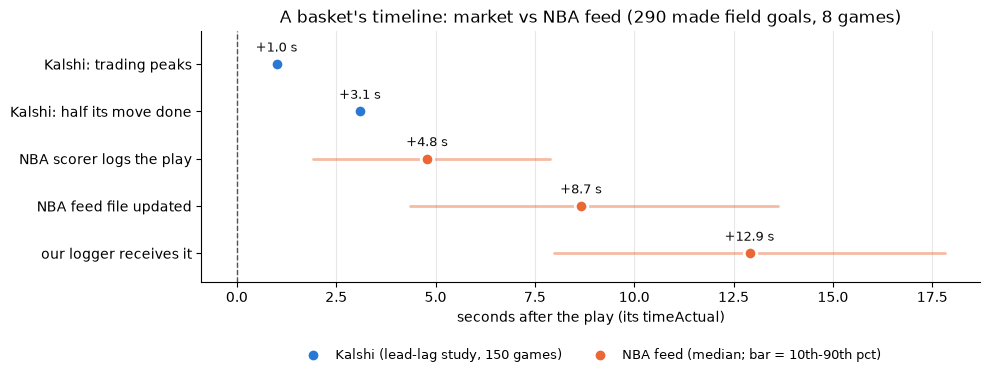

,games,plays,feed median,feed p10,feed p90,share <= 2s,share <= 3.1s,published median,entered median
all,8.0,290.0,12.90,7.98,17.81,0.0,0.0,8.66,4.79
Q1,3.0,58.0,13.04,7.54,18.35,0.0,0.0,9.18,5.39
Q2,5.0,70.0,12.40,8.41,17.21,0.0,0.0,8.21,4.74
Q3,5.0,67.0,14.30,7.75,18.61,0.0,0.0,9.23,5.26
Q4,8.0,85.0,13.05,8.22,16.76,0.0,0.0,8.47,4.34
OT,1.0,10.0,11.28,6.31,13.13,0.0,0.0,5.72,2.83


In [3]:
fd.timeline(delays)
plt.show()
table = pd.concat([fd.describe(delays), fd.describe(delays, "period")])
table.index = ["all"] + [f"Q{p}" if int(p) <= 4 else "OT" for p in table.index[1:]]
table.round(2)

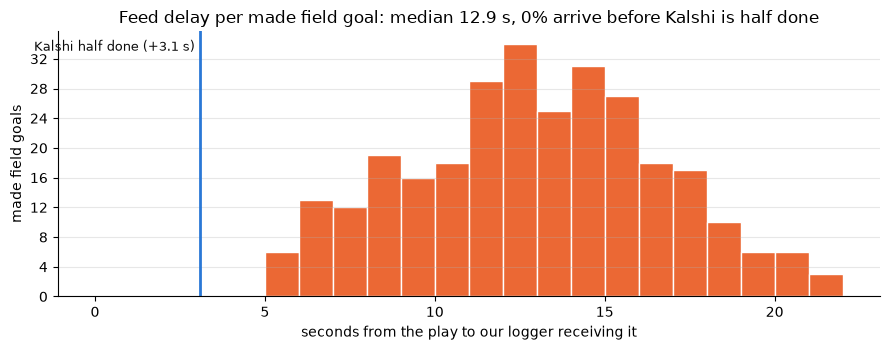

In [4]:
fd.distribution(delays)
plt.show()

## 2. Is it the same in every game?

Each faint tick is one basket. The median is between 11 and 14.5 s in every game, so the
lag comes from the feed itself, not from one slow game.

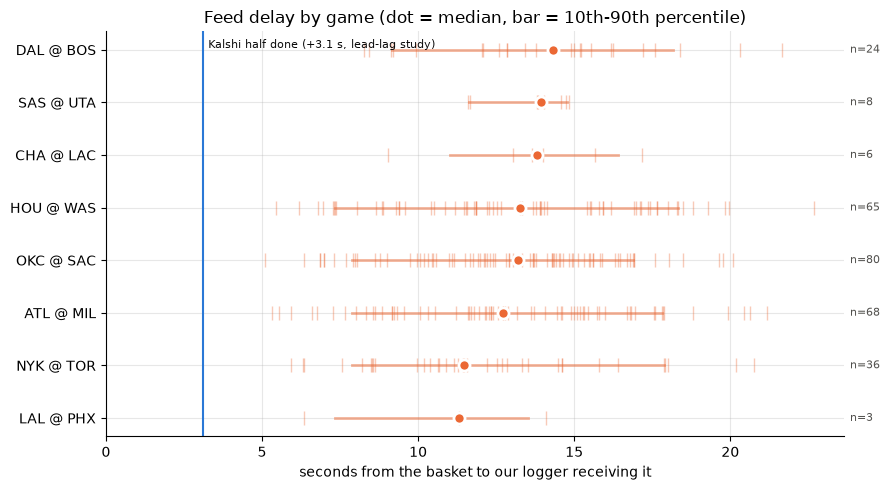

,plays,feed median,feed p10,feed p90
ATL @ MIL,68.0,12.72,7.89,17.82
CHA @ LAC,6.0,13.82,11.04,16.41
DAL @ BOS,24.0,14.33,9.15,18.15
HOU @ WAS,65.0,13.26,7.35,18.32
LAL @ PHX,3.0,11.31,7.35,13.53
NYK @ TOR,36.0,11.45,7.87,17.89
OKC @ SAC,80.0,13.18,7.90,16.87
SAS @ UTA,8.0,13.94,11.64,14.77


In [5]:
lv.by_game(night)
plt.show()
by_game = delays.merge(night.games, on="game_id").assign(game=lambda d: d["away"] + " @ " + d["home"])
fd.describe(by_game, "game")[["plays", "feed median", "feed p10", "feed p90"]].round(2)

## 3. The race after a basket: Kalshi vs our feed, same night

The same method as the lead-lag study, on last night's games. Take every **isolated** made field
goal (no other score within 20 s either side) with the price between 3 and 97 cents. Line up
Kalshi's price around it, signed toward the scoring team, and average. Shaded bands are 95%
intervals from resampling games.

- **Blue, Kalshi trades:** what the market actually did, on the exchange's clock.
- **Purple, the Kalshi mid our logger polled:** what a bot polling Kalshi's public REST API
  would have seen.
- **Orange:** when our feed delivered the basket.

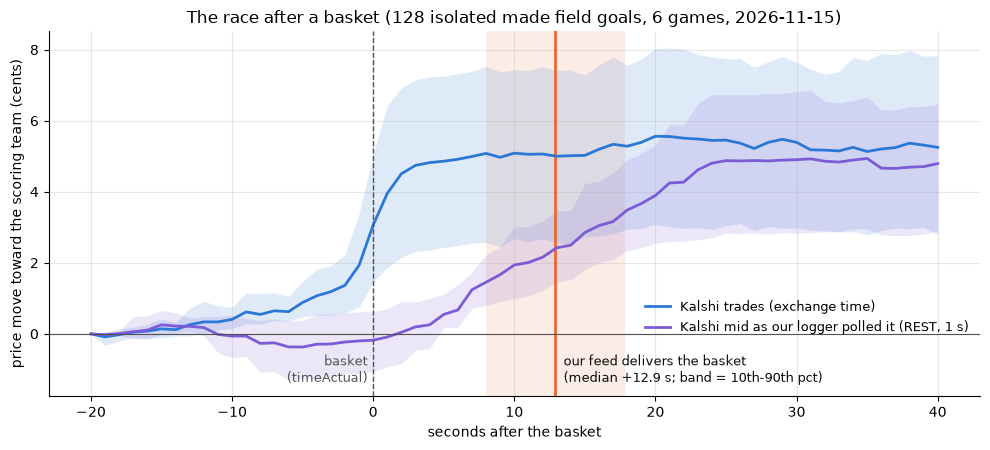

,seconds after basket,lo,hi,Kalshi move already done
Kalshi trades: half the move done,-0.39,-0.76,0.41,0.50
Kalshi book as we polled it: half the move done,12.93,9.20,15.59,0.95
"NBA feed delivers the basket (median, 10th-90th pct)",12.90,7.98,17.81,0.96


In [6]:
events = lv.basket_events(night)
curve, half = lv.response(events)
lv.race_chart(night, events, curve)
plt.show()
lv.race(night, curve, half).round(2)

## 4. The Kalshi prices we polled were about 13 s old

The purple curve trails the blue one by more than 10 s, so the REST snapshot itself must
be stale. To check that without using any basket, compare the **total volume** each polled
snapshot reported against Kalshi's trade log. If a snapshot is L seconds old, its volume
matches the trade log's running total from L seconds before we got it. Below is the L that
matches best in each game (games with under 1,000 trades are left out). The mismatch drops by more than half at that lag.

In [7]:
lv.book_staleness(night).round(1)

,book is this many s old,volume mismatch at that lag,mismatch if fresh (0 s)
game,,,
LAL @ PHX,12.5,2072.0,4482.4
CHA @ LAC,13.5,1701.1,4110.6
SAS @ UTA,13.0,4277.0,9445.8
NYK @ TOR,13.5,2581.9,6799.6
HOU @ WAS,13.0,735.4,2003.9
ATL @ MIL,14.0,2439.8,5713.7
OKC @ SAC,14.0,1931.5,4540.1


## 5. One example stretch

The 4-minute stretch where baskets moved the price most. Dots are trades, the purple step
line is the mid as we polled it, dashed lines are baskets, and orange arrows run from each
basket to when our feed received it. Baskets without an arrow weren't timed live, because
another play arrived in the same poll window. The trades jump at the dashed line; the polled
mid and our feed both catch up about 10-15 s later.

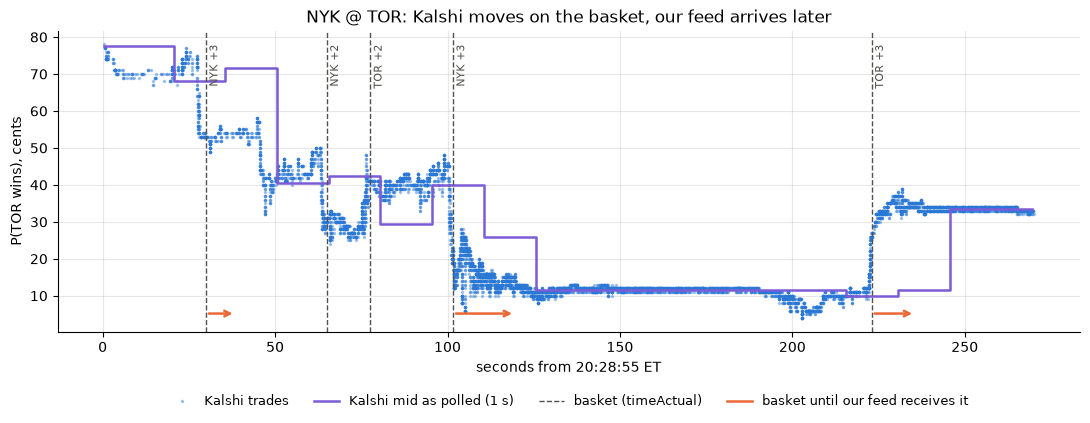

In [8]:
lv.example(night, events)
plt.show()

## Conclusions

**1. The free NBA feed delivers a basket a median 12.9 s after it happens** (10th-90th
percentile 8.0-17.8 s, 290 made field goals, 8 games). None arrived within 3.1 s. About 4.8 s
of that is the scorer logging the play, the file is republished by 8.7 s, and the CDN cache
adds about 4 s more. The median is 11-14.5 s in every game and every quarter.

**2. Last night Kalshi's trades had done half their move at about the basket's timestamp**
(-0.4 s, 95% interval -0.8 to +0.4 s; 128 isolated baskets, 6 games). By the time our feed
delivered the basket, about 95% of the move was done. This is faster than the lead-lag study's
+3.1 s, but it is one night against 150 games, field goals only, with a different averaging
window. Either way the conclusion is the same: **we can't win the race with the free feed.**

**3. Kalshi's public REST snapshot was about 13 s stale too** (12.5-14 s in all 7 games
with enough trades). A bot that polls REST is late on the market side as well as on the NBA
side, and it would be quoting around a price that has already moved.

**What this means for the backtest:**
- Simulate fills against **Kalshi trades** (exchange time), not our polled `book.csv`. The polled
  book is fine for spreads and depth, but not for timing.
- Run the backtest with feed delay as a setting: **0 s** (ideal), **3 s** (a paid
  low-latency feed) and **12.9 s** (what we have). With 12.9 s, the edge has to come from
  the quoting rule: widen or pull quotes when the price jumps, without waiting for the feed.
- A live bot would need Kalshi's WebSocket feed, which needs an API key, for its market
  data. Polling REST is not enough.

**Caveats:** one night, and the market-side numbers use 6 games. Plays from the 403 hour
weren't timed. The clock correction moved about 1.4 s once around 22:10, which barely
changes the median.